In [1]:
# Packages to import
import numpy as np
import matplotlib.pyplot as plt
import uproot
import awkward as ak

In [2]:
# Constants

NA = 6.022 * 10**23 # Avogadro's number
e = 1.602 * 10 ** -19 # elementary charge, C
me = 9.109 * 10 ** -31 # electron mass, kg
E0 = 8.85 * 10 ** -12 # epsilon_0, SI units
c = 3 * 10 ** 8 # speed of light, m/s
M = 0.001 # molar mass constant in kg/mol

In [3]:
# Classes

# Defines particle types
class Particle:
    def __init__(self, name, mass, charge):
        self.name = name
        self.mass = mass # in kg
        self.charge = charge # in units of e

# defines materials
class Material:
    def __init__(self, name, Z, A, rho, I):
        self.name = name
        self.Z = Z
        self.A = A
        self.rho = rho # in kg/m^3
        self.I = I # in J

# computes dE/dx from Bethe-Bloch equation
def dEdx(b, particle, material):
    v = b * c
    zp = particle.charge
    Z = material.Z
    A = material.A
    rho = material.rho
    I = material.I
    return (4*np.pi*NA * Z * rho * (zp**2) / (A*M*me*(v**2))) * (e ** 2 / ((4*np.pi*E0)))**2 * (np.log(2 * me * v**2 /(I*(1-b**2))) - b ** 2)

# Defines detector layers
class Layer: 
    def __init__(self, material, thickness):
        self.material = material
        self.thickness = thickness # in meters

# Creates a detector with layers as a list
class Detector:
    def __init__(self, layers):
        self.layers = layers

In [4]:
# Providing initial energy, allows for annihilation event

def simulateE2(particle, detector, E_i, dx=1*10**-6):
    b = (1 - 1/(1+(E_i/(particle.mass*c**2)))**2) ** 0.5 # Compute initial beta value
    print(particle.name + " " + str(b))
    E = E_i 
    xVals = []
    eVals = []
    pVals = []
    eDep = []
    depE = 0 # tracks total energy deposited
    interactionProb = 0.001 # for dark matter only
    x_tot = 0 # tracks total distance traveled
    for layer in detector.layers: # loop across layers
        x = 0 # tracks distance traveled through layer
        while x < layer.thickness and E > 0:
            
            if particle.name == "wimp": # dark matter, no charge so not affected by Bethe-Bloch. Beta calculation not needed.
                if np.random.random() < interactionProb:
                    lostE = np.random.uniform(0.01*1.602*10e-13, 0.1*1.602*10e-13) # some energy deposited through stochastic processes
                    if lostE >= E: # particle would lose all its remaining energy 
                        pVals.append(E/dx/(1.602*10e-11)) # stores in MeV/cm
                        xVals.append(x_tot*100) # stores in cm
                        depE += E 
                        eDep.append(depE/(1.602*10e-13)) # stores in MeV
                        E = 0
                        eVals.append(E/(1.602*10e-13)) # stores in MeV 
                        break
                    E -= lostE
                    depE += lostE
                    eVals.append(E/(1.602*10e-13))
                    eDep.append(depE/(1.602*10e-13)) # stores in MeV
                    pVals.append(lostE/dx/(1.602*10e-11)) # stores in MeV/cm
                    x += dx
                    x_tot += dx
                    xVals.append(x_tot*100) # stores in cm
                    continue
                x += dx
                x_tot += dx
                xVals.append(x_tot*100) # stores in cm
                eVals.append(E/(1.602*10e-13)) # stores in MeV
                pVals.append(0) # stores in MeV/cm
                eDep.append(depE/(1.602*10e-13))
                continue

            dex = dEdx(b, particle, layer.material) # calls Bethe-Bloch equation for material and particle type
            x += dx
            x_tot += dx
            if dex*dx >= E or dex < 0: # particle would lose all its remaining energy 
                pVals.append(E/dx/(1.602*10e-11)) # stores in MeV/cm
                xVals.append(x_tot*100) # stores in cm
                if particle.name == "antiproton":
                    depE += 2*particle.mass*c**2 # antiproton annihilates with an atom
                    print("annihilation event")
                depE += E 
                eDep.append(depE/(1.602*10e-13)) # stores in MeV
                E = 0
                eVals.append(E/(1.602*10e-13)) # stores in MeV 
                break
                
            E -= dex*dx # compute new energy
            depE += dex*dx # compute new energy

            eVals.append(E/(1.602*10e-13)) # stores in MeV
            xVals.append(x_tot*100) # stores in cm
            pVals.append(dex/(1.602*10e-11)) # stores in MeV/cm
            eDep.append(depE/(1.602*10e-13)) # store deposited energy at the location in MeV
            b = (1 - 1/(1+(E/(particle.mass*c**2)))**2) ** 0.5 # Compute new beta value
    return xVals, eVals, pVals, eDep

In [5]:
# Particle types

proton = Particle("proton", 1.673*10**-27, 1)
muon = Particle("muon", 1.883*10**-28, 1)
pion = Particle("pion", 2.49*10**-28, 1)
antiproton = Particle("antiproton", 1.673*10**-27, 1)
wimp = Particle("wimp", 2.193*10e-25, 0)

In [6]:
# Material types

tungsten = Material("tungsten", 74, 184, 19250, 727 * 1.602*10**-19)
lead = Material("lead", 82, 207, 11348, 820 * 1.602*10**-19)
iron = Material("iron", 26, 56, 7874, 260 * 1.602*10**-19)
copper = Material("copper", 29, 63, 8960, 290 * 1.602*10**-19)
uranium = Material("uranium", 92, 238, 19100, 920 * 1.602*10**-19)

In [7]:
# plotting functions
def plotPower(energy, power, label):
    plt.plot(energy, power, label=label)
    plt.xlabel("Energy (MeV)")
    plt.ylabel("Stopping Power (MeV/cm)")
    plt.legend()
    
def plotEX(dist, energy, label):
    plt.plot(dist, energy, label=label)
    plt.xlabel("distance traveled (cm)")
    plt.ylabel("Particle energy (MeV)")
    plt.legend()

def plotEDep(dist, dep, label):
    plt.plot(dist, dep, label=label)
    plt.xlabel("distance traveled (cm)")
    plt.ylabel("Particle energy deposited (MeV)")
    plt.yscale("log")
    plt.legend()

proton 0.7799125380898397
antiproton 0.7799125380898397
annihilation event
muon 0.987365129927712
pion 0.9799264231093189
wimp 0.030188893406173083


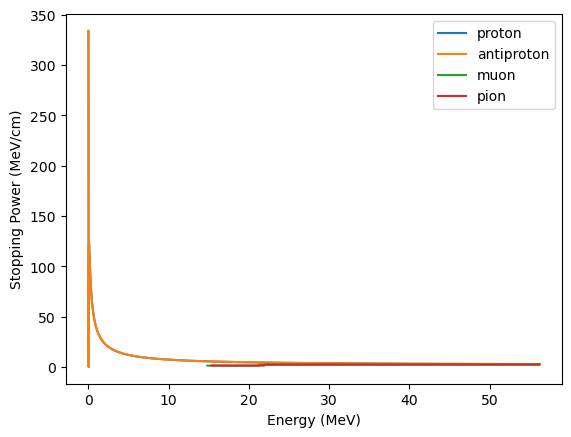

In [8]:
# Lists materials that make up the detector

detector = Detector([Layer(tungsten, 0.15), Layer(lead, 0.05)])

# Main function
x_p, E_p, P_p, D_p = simulateE2(proton, detector, 9*10e-12)
x_a, E_a, P_a, D_a = simulateE2(antiproton, detector, 9*10e-12)
x_m, E_m, P_m, D_m = simulateE2(muon, detector, 9*10e-12)
x_pi, E_pi, P_pi, D_pi = simulateE2(pion, detector, 9*10e-12)
x_w, E_w, P_w, D_w = simulateE2(wimp, detector, 9*10e-12)

plotPower(E_p, P_p, label="proton")
plotPower(E_a, P_a, label="antiproton")
plotPower(E_m, P_m, label="muon")
plotPower(E_pi, P_pi, label="pion")

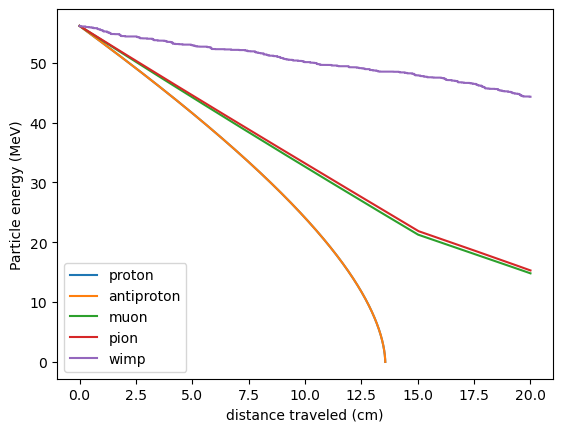

In [9]:
plotEX(x_p, E_p, label="proton")
plotEX(x_a, E_a, label="antiproton")
plotEX(x_m, E_m, label="muon")
plotEX(x_pi, E_pi, label="pion")
plotEX(x_w, E_w, label="wimp")

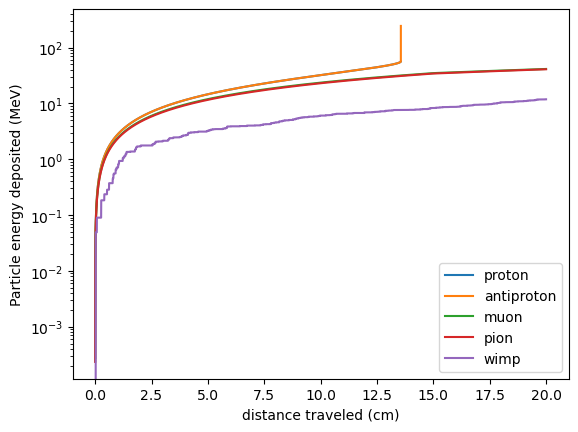

In [10]:
plotEDep(x_p, D_p, label="proton")
plotEDep(x_a, D_a, label="antiproton")
plotEDep(x_m, D_m, label="muon")
plotEDep(x_pi, D_pi, label="pion")
plotEDep(x_w, D_w, label="wimp")

In [ ]:
### OLDER SIMULATION METHODS WITH PROVIDING INITIAL BETA AND A CUTOFF WITHOUT SETTING PARTICLE ENERGY TO 0
# Providing initial beta

def simulate(particle, detector, b0, dx=1*10**-6):
    b = b0
    E = (1 / (1 - b ** 2)**0.5 - 1) * particle.mass * c ** 2 # calculate initial kinetic energy
    xVals = []
    eVals = []
    pVals = []
    x_tot = 0 # tracks total distance traveled
    for layer in detector.layers:
        x = 0 # tracks distance traveled through layer
        
        while x < layer.thickness and E > 0:
            dex = dEdx(b, particle, layer.material)
            E -= dex*dx # compute new energy
            x += dx
            x_tot += dx
            
            if E <= 0 or dex < 0: # check if particle has lost all its energy
                break
                
            eVals.append(E)
            xVals.append(x_tot)
            pVals.append(dex)
            
            b = (1 - 1/(1+(E/(particle.mass*c**2)))**2) ** 0.5 # Compute new beta value
    return xVals, eVals, pVals

# Lists materials that make up the detector

detector = Detector([Layer(tungsten, 1)])

# Main function
x_p, E_p, P_p = simulate(proton, detector, 0.9)
x_a, E_a, P_a = simulate(antiproton, detector, 0.9)
x_m, E_m, P_m = simulate(muon, detector, 0.9)
x_pi, E_pi, P_pi = simulate(pion, detector, 0.9)

plotPower(E_p, P_p, label="proton")
plotPower(E_a, P_a, label="antiproton")
plotPower(E_m, P_m, label="muon")
plotPower(E_pi, P_pi, label="pion")

In [ ]:
# Providing initial energy

def simulateE(particle, detector, E_i, dx=1*10**-6):
    b = (1 - 1/(1+(E_i/(particle.mass*c**2)))**2) ** 0.5 # Compute initial beta value
    print(particle.name + " " + str(b))
    E = E_i 
    xVals = []
    eVals = []
    pVals = []
    x_tot = 0 # tracks total distance traveled
    for layer in detector.layers:
        x = 0 # tracks distance traveled through layer
        print(dEdx(b, particle, layer.material))
        while x < layer.thickness and E > 0:
            dex = dEdx(b, particle, layer.material)
            E -= dex*dx # compute new energy
            x += dx
            x_tot += dx
            
            if E <= 0 or dex < 0: # check if particle has lost all its energy
                break
                
            eVals.append(E)
            xVals.append(x_tot)
            pVals.append(dex)
            
            b = (1 - 1/(1+(E/(particle.mass*c**2)))**2) ** 0.5 # Compute new beta value
    return xVals, eVals, pVals

# Lists materials that make up the detector

detector = Detector([Layer(tungsten, 0.05), Layer(lead, 0.25), Layer(tungsten, 0.05), Layer(lead, 0.25)])

# Main function
x_p, E_p, P_p = simulateE(proton, detector, 3*10e-11)
x_a, E_a, P_a = simulateE(proton, detector, 3*10e-11)
x_m, E_m, P_m = simulateE(muon, detector, 3*10e-11)
x_pi, E_pi, P_pi = simulateE(pion, detector, 3*10e-11)

plotPower(E_p, P_p, label="proton")
plotPower(E_a, P_a, label="antiproton")
plotPower(E_m, P_m, label="muon")
plotPower(E_pi, P_pi, label="pion")